# 04 · ¿Los descuentos grandes indican juegos peores?
**Responsable:** Fabiola

**Entrada:** juegos.parquet

**Salida:** figuras y conclusión para la presentación

**Pasos:**
1. Dibujar las flechas.
2. Ver la relación cruda, el % positivo según el nivel de descuento.
3. Repetir la comparación dentro de grupos de antigüedad.
4. Concluir y anotar las limitaciones.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # para poder importar src/ desde notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as C
from src.datos import cargar_juegos

df = cargar_juegos()
df.shape

(44568, 37)

## 1. El dibujo
Antes de comparar hay que escribir qué creemos que causa qué, porque los datos solos no distinguen la dirección de una flecha. Las flechas que creemos son estas:

antigüedad -> descuento: los juegos viejos suelen rebajarse más.

antigüedad -> calidad: el % positivo cambia según qué tan viejo es el juego.

calidad -> descuento: un juego mal recibido vende poco, y por eso se rebaja más.

descuento -> calidad: es la flecha menos creíble, porque bajar el precio no cambia el juego. Lo mucho que puede cambiar es quién lo compra y lo reseña.

Lo que queremos saber es si un descuento grande sirve como señal de un juego peor. La antigüedad influye en el descuento y también en las reseñas, entonces es un confusor, y cuando una tercera variable influye en las dos cosas hay que comparar dentro de grupos parecidos. Esto igual no dice cuál flecha entre descuento y calidad es la correcta.

Quitamos los juegos gratis porque no se les puede hacer descuento.

In [2]:
AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

pagados = df[~df["es_gratis"]].copy()
pagados["pct"] = pagados["pct_positivo"] * 100
pagados["nivel"] = pd.cut(pagados["descuento_actual"], C.CORTES_DESCUENTO, labels=C.NIVELES_DESCUENTO)
pagados["grupo"] = pd.cut(pagados["antiguedad_anios"], C.CORTES_ANTIGUEDAD, labels=C.GRUPOS_ANTIGUEDAD)

print("juegos de pago:", len(pagados), "de", len(df))

juegos de pago: 38603 de 44568


## 2. Comparación cruda
Además del % positivo vemos si los grupos son comparables, porque si los juegos de cada nivel son distintos en otras cosas, la diferencia puede venir de ahí y no del descuento.

In [3]:
cruda = pagados.groupby("nivel", observed=True).agg(
    juegos=("appid", "size"),
    pct_positivo=("pct", "mean"),
    antiguedad=("antiguedad_anios", "mean"),
    precio_lista=("precio_lista_usd", "mean"),
    resenas_mediana=("total_resenas", "median"),
)
print(cruda.round(1))

dif_vs_sin = cruda.loc["más de 60 %", "pct_positivo"] - cruda.loc["sin descuento", "pct_positivo"]
dif_vs_chico = cruda.loc["más de 60 %", "pct_positivo"] - cruda.loc["hasta 30 %", "pct_positivo"]
print()
print("más de 60 % menos sin descuento:", round(dif_vs_sin, 1), "puntos")
print("más de 60 % menos hasta 30 %:   ", round(dif_vs_chico, 1), "puntos")

               juegos  pct_positivo  antiguedad  precio_lista  resenas_mediana
nivel                                                                         
sin descuento   16395          76.2         6.9           7.7             66.0
hasta 30 %       2988          84.9         4.0          11.9            136.0
30 a 60 %        8858          81.0         5.6          12.0            138.0
más de 60 %     10362          76.1         8.0          14.3            208.0

más de 60 % menos sin descuento: -0.1 puntos
más de 60 % menos hasta 30 %:    -8.8 puntos


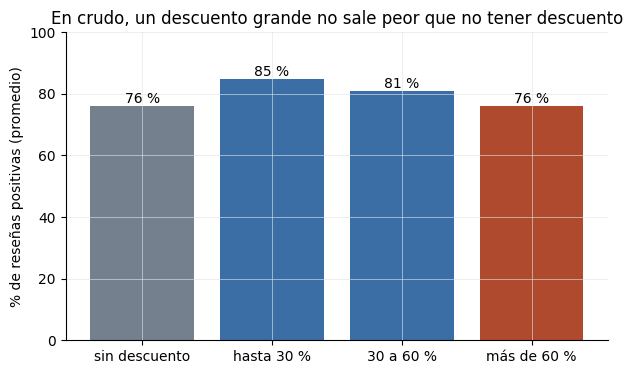

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(cruda.index.astype(str), cruda["pct_positivo"], color=[GRIS, AZUL, AZUL, ROJO])
for i, v in enumerate(cruda["pct_positivo"]):
    ax.text(i, v + 1, f"{v:.0f} %", ha="center")
ax.set_ylim(0, 100)
ax.set_ylabel("% de reseñas positivas (promedio)")
ax.set_title("En crudo, un descuento grande no sale peor que no tener descuento")
eje_limpio(ax)
fig.savefig(C.FIGURAS / "04_cruda.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Comparación dentro de grupos de antigüedad
Primero confirmamos que la antigüedad sí está relacionada con las dos cosas, y después repetimos la comparación dentro de cada grupo, para comparar juegos de edad parecida.

In [5]:
confusor = pagados.groupby("grupo", observed=True).agg(
    juegos=("appid", "size"),
    pct_positivo=("pct", "mean"),
    descuento_promedio=("descuento_actual", "mean"),
)
confusor["descuento_promedio"] = confusor["descuento_promedio"] * 100
print(confusor.round(1))

                juegos  pct_positivo  descuento_promedio
grupo                                                   
0 a 2 años        2967          85.1                27.0
2 a 5 años       12064          81.8                33.1
5 a 10 años      16204          76.2                33.4
más de 10 años    7368          72.6                40.7


In [6]:
por_grupo = pagados.groupby(["grupo", "nivel"], observed=True)["pct"].mean().unstack()
conteo = pagados.groupby(["grupo", "nivel"], observed=True).size().unstack()

por_grupo["dif_vs_sin"] = por_grupo["más de 60 %"] - por_grupo["sin descuento"]
por_grupo["dif_vs_chico"] = por_grupo["más de 60 %"] - por_grupo["hasta 30 %"]

print(por_grupo.round(1))
print()
print("juegos en cada casilla:")
print(conteo)
print()
print("más de 60 % menos sin descuento | cruda:", round(dif_vs_sin, 1),
      "| promedio dentro de grupos:", round(por_grupo["dif_vs_sin"].mean(), 1))
print("más de 60 % menos hasta 30 %    | cruda:", round(dif_vs_chico, 1),
      "| promedio dentro de grupos:", round(por_grupo["dif_vs_chico"].mean(), 1))

nivel           sin descuento  hasta 30 %  30 a 60 %  más de 60 %  dif_vs_sin  \
grupo                                                                           
0 a 2 años               85.2        87.2       84.2         80.0        -5.2   
2 a 5 años               81.5        85.7       83.1         78.5        -2.9   
5 a 10 años              74.8        82.1       79.2         75.5         0.6   
más de 10 años           69.0        76.9       76.3         74.7         5.7   

nivel           dif_vs_chico  
grupo                         
0 a 2 años              -7.2  
2 a 5 años              -7.1  
5 a 10 años             -6.6  
más de 10 años          -2.2  

juegos en cada casilla:
nivel           sin descuento  hasta 30 %  30 a 60 %  más de 60 %
grupo                                                            
0 a 2 años                946         843        968          210
2 a 5 años               4611        1321       3685         2447
5 a 10 años              7750         

In [7]:
# Lo mismo con la métrica del proyecto: % de juegos bien recibidos (más de 80 % positivo)
bien = pagados.groupby(["grupo", "nivel"], observed=True)["bien_recibido"].mean().unstack() * 100
bien["dif_vs_sin"] = bien["más de 60 %"] - bien["sin descuento"]
bien["dif_vs_chico"] = bien["más de 60 %"] - bien["hasta 30 %"]
print(bien.round(1))
print()
print("promedio dentro de grupos | vs sin:", round(bien["dif_vs_sin"].mean(), 1),
      "| vs hasta 30 %:", round(bien["dif_vs_chico"].mean(), 1))

nivel           sin descuento  hasta 30 %  30 a 60 %  más de 60 %  dif_vs_sin  \
grupo                                                                           
0 a 2 años               71.8        78.4       69.2         53.3       -18.4   
2 a 5 años               61.7        74.8       66.8         53.3        -8.4   
5 a 10 años              46.3        64.1       58.6         46.6         0.2   
más de 10 años           34.3        47.8       52.0         45.0        10.8   

nivel           dif_vs_chico  
grupo                         
0 a 2 años             -25.1  
2 a 5 años             -21.5  
5 a 10 años            -17.5  
más de 10 años          -2.7  

promedio dentro de grupos | vs sin: -4.0 | vs hasta 30 %: -16.7


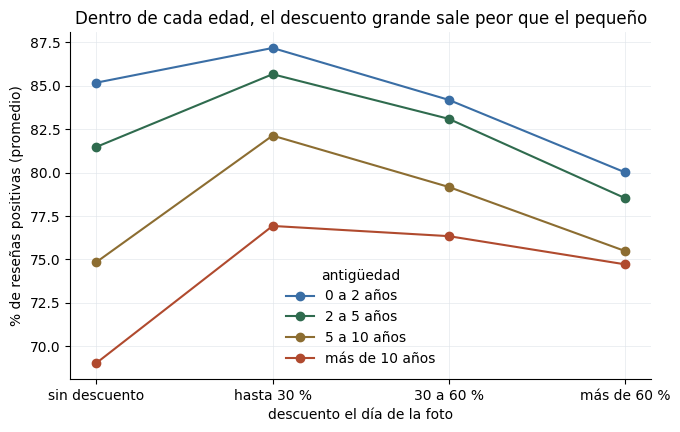

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
colores = [AZUL, "#2F6B4E", "#8C6D31", ROJO]
for grupo, color in zip(C.GRUPOS_ANTIGUEDAD, colores):
    ax.plot(C.NIVELES_DESCUENTO, por_grupo.loc[grupo, C.NIVELES_DESCUENTO], "o-", color=color, label=grupo)
ax.set_ylabel("% de reseñas positivas (promedio)")
ax.set_xlabel("descuento el día de la foto")
ax.set_title("Dentro de cada edad, el descuento grande sale peor que el pequeño")
ax.legend(title="antigüedad", frameon=False)
eje_limpio(ax)
fig.savefig(C.FIGURAS / "04_por_antiguedad.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusión y limitaciones
Contra no tener descuento no se ve un castigo general. En crudo la diferencia es casi cero (-0.1 puntos) y el promedio dentro de grupos también (-0.4), pero el signo cambia, en los juegos nuevos el descuento grande sale peor (-5.2) y en los de más de 10 años sale mejor (5.7). El total esconde esas dos cosas.

Contra un descuento pequeño sí sale peor. La diferencia baja de 8.8 puntos en crudo a 5.8 dentro de grupos, osea que la antigüedad explica una parte pero no todo. Con la métrica del proyecto, que es el % de juegos bien recibidos, la diferencia es de 16.7 puntos.

Para la decisión, un descuento grande no basta para descartar un juego, pero tampoco es irrelevante. En la oferta casi todo va a tener descuento, entonces la comparación que sirve es contra el descuento pequeño. Y como el modelo del notebook 02 no usa el descuento, la lista final no lo está corrigiendo.

Lo que no se puede concluir:

No se puede decir que el descuento cause peores reseñas. Aprendimos que predecir no es lo mismo que intervenir, y lo más creíble aquí es al revés, que un juego mal recibido se rebaje más, pero estos datos no distinguen la dirección.

El descuento es el de un solo día, y un juego sin descuento ese día pudo tenerlo otro, entonces ese grupo está mezclado. Puede ser la razón de que salga peor que el de descuento pequeño en las cuatro edades, pero no lo podemos separar.

El precio original queda como confusor sin separar, porque los de más de 60 % cuestan casi el doble que los que no tienen descuento (14.3 vs 7.7 dólares).

La popularidad no la separamos a propósito. Las reseñas y los dueños vienen después del descuento y de la calidad, y separar por algo que viene después puede esconder el efecto o inventar una relación que no existe.

Solo hay juegos con al menos 20 reseñas y que siguen en la tienda. Es mirar solo a los que quedaron, y eso también puede crear relaciones que no existen entre todos los juegos.

La fecha exacta en que se tomaron los datos no se conoce, y casi no hay juegos con reseñas desde mediados de 2025, entonces el grupo de 0 a 2 años empieza en realidad cerca de 1 año.

Algunos grupos son chicos, como los juegos de más de 10 años con descuento pequeño (134 juegos). Ahí el promedio es menos confiable y la diferencia no se distingue de cero.